# Laboratorio 24. Optimización de hiperparámetros con MNIST

**Asignatura:** Analítica de Datos  
**Universidad:** Universidad Cooperativa de Colombia  
**Docente:** Luis Miguel Gómez Meneses  
**Clase 12 — 6 de noviembre de 2026**  
**Duración orientativa:** 40 minutos, con el código preparado.


Trabajaremos con **el mismo MNIST de dígitos manuscritos utilizado en el laboratorio 23**.
Cada imagen corresponde a un dígito entre 0 y 9. Este laboratorio es independiente:
descarga los datos y crea sus propios modelos, sin necesitar archivos del laboratorio anterior.

## Objetivo

Comparar seis redes neuronales cambiando el número de neuronas y la tasa de aprendizaje,
seleccionar una configuración mediante validación y evaluar el modelo elegido en prueba.

Al terminar tendrás una tabla comparativa, curvas de aprendizaje, una matriz de confusión
y un archivo `modelo_mnist.keras` para el laboratorio 25.

### Cómo trabajar en Colab

1. Carga este archivo `.ipynb` en Google Colab y guarda una copia.
2. Ejecuta las celdas de arriba hacia abajo. Una GPU es opcional para estas redes pequeñas.
3. Antes de iniciar el entrenamiento, revisa las configuraciones. Después no las cambies
   usando el resultado de prueba.
4. Responde las preguntas en las celdas de Markdown y descarga el ZIP final.

Los tiempos dependen del equipo. Todos los resultados numéricos se calculan al ejecutar
el notebook: no se presupone cuál configuración ganará.


## 1. Librerías y entorno

Usaremos TensorFlow/Keras para las redes, scikit-learn para las particiones y métricas,
NumPy y pandas para los datos, y Matplotlib para las gráficas.
La siguiente celda instala **únicamente las dependencias que falten**.
En Colab normalmente ya están disponibles.


In [1]:
import importlib.util
import subprocess
import sys
dependencias = {
    "tensorflow": "tensorflow", "numpy": "numpy", "pandas": "pandas",
    "matplotlib": "matplotlib", "sklearn": "scikit-learn", "PIL": "Pillow",
    "IPython": "ipython"
}
faltantes = [paquete for modulo, paquete in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import json
import time
import shutil
from pathlib import Path
from datetime import datetime
from itertools import product
from importlib.metadata import version as version_paquete
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from PIL import Image
from IPython.display import display, Markdown, FileLink
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLOR_ENT = "#14484F"
COLOR_VAL = "#C2571A"
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))


Python: 3.13.18
TensorFlow: 2.21.0
GPU disponibles: []


## 2. Configuración común

Evaluaremos **2 tamaños de capa oculta × 3 tasas = 6 configuraciones**.

| Elemento | Valor |
|---|---|
| Neuronas en una capa oculta | 32 y 128 |
| Tasa de aprendizaje de Adam | 0.01, 0.001 y 0.0001 |
| Activación oculta / salida | ReLU / softmax |
| Lote / máximo de épocas | 128 / 12 |
| Parada temprana | `val_loss`, paciencia 3, restaurar mejores pesos |
| Criterio de selección | Menor pérdida de validación del modelo restaurado |

Usaremos la misma partición y semilla para todos. La semilla reduce fuentes de variación,
pero no demuestra que una diferencia pequeña sea estable entre ejecuciones o equipos.
Si se modifica el presupuesto por tiempo, debe hacerse **antes del experimento y para
todos los candidatos por igual**.


In [2]:
SEMILLA = 42
N_ENTRENAMIENTO = 12_000
N_VALIDACION = 3_000
NEURONAS = [32, 128]
TASAS = [0.01, 0.001, 0.0001]
TAM_LOTE = 128
MAX_EPOCAS = 12
PACIENCIA = 3
tf.keras.utils.set_random_seed(SEMILLA)
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:
    print("Esta versión no ofrece enable_op_determinism; se conservan las semillas.")

# Cada ejecución crea su propia carpeta para conservar los resultados anteriores.
ID_EJECUCION = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
CARPETA = Path("laboratorio24_mnist") / ID_EJECUCION
CANDIDATOS_DIR = CARPETA / "candidatos"
FIGURAS_DIR = CARPETA / "figuras"
for carpeta in (CANDIDATOS_DIR, FIGURAS_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Resultados de esta ejecución:", CARPETA.resolve())


Resultados de esta ejecución: /content/laboratorio24_mnist/20261106_200022_397445


## 3. Carga de MNIST

MNIST contiene imágenes en escala de grises de **28 × 28 píxeles** y etiquetas enteras
de **0 a 9**. La carga oficial entrega 60.000 imágenes de entrenamiento y 10.000 de prueba.

La primera descarga requiere conexión a internet. Se conserva el conjunto oficial de prueba
para el final. Sus etiquetas no se utilizarán para elegir configuraciones.

**Las imágenes se mantienen en 0–255.** El reescalado a 0–1 se incluirá dentro de la red,
por lo que no debemos dividir nuevamente los arreglos entre 255.


In [17]:
(x_original, y_original), (x_prueba, y_prueba) = tf.keras.datasets.mnist.load_data()
assert x_original.shape == (60_000, 28, 28)
assert x_prueba.shape == (10_000, 28, 28)
assert set(np.unique(y_original)) == set(range(10))
print("Conjunto original de entrenamiento:", x_original.shape)
print("Etiquetas de entrenamiento:", y_original.shape)
print("Conjunto oficial de prueba reservado:", x_prueba.shape)
print("Tipo de las imágenes:", x_original.dtype)
print("Rango del conjunto original:", int(x_original.min()), "a", int(x_original.max()))

Conjunto original de entrenamiento: (60000, 28, 28)
Etiquetas de entrenamiento: (60000,)
Conjunto oficial de prueba reservado: (10000, 28, 28)
Tipo de las imágenes: uint8
Rango del conjunto original: 0 a 255


## 4. Partición estratificada

Para ajustar el tiempo de clase, seleccionaremos 15.000 imágenes de las 60.000 originales
y las separaremos en 12.000 de entrenamiento y 3.000 de validación. Los otros 45.000 ejemplos
no se usarán en esta práctica.

**Estratificar** busca conservar aproximadamente la proporción de cada dígito.
Guardaremos los índices originales para poder reconstruir las particiones.


In [4]:
indices = np.arange(len(y_original))
idx_muestra, idx_no_usados = train_test_split(
    indices,
    train_size=N_ENTRENAMIENTO + N_VALIDACION,
    random_state=SEMILLA,
    stratify=y_original
)
idx_ent, idx_val = train_test_split(
    idx_muestra,
    train_size=N_ENTRENAMIENTO,
    test_size=N_VALIDACION,
    random_state=SEMILLA,
    stratify=y_original[idx_muestra]
)
x_ent, y_ent = x_original[idx_ent], y_original[idx_ent]
x_val, y_val = x_original[idx_val], y_original[idx_val]
assert len(np.intersect1d(idx_ent, idx_val)) == 0
assert len(np.unique(np.concatenate([idx_ent, idx_val]))) == 15_000
assert len(idx_no_usados) == 45_000
tabla_particiones = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba oficial", "No utilizados"],
    "Imágenes": [len(y_ent), len(y_val), len(y_prueba), len(idx_no_usados)],
    "Función": ["Ajustar pesos y bias", "Seleccionar configuración",
                "Evaluar el modelo elegido", "Fuera de esta práctica"]
})
display(tabla_particiones)
np.savez_compressed(CARPETA / "indices_particiones.npz",
                    entrenamiento=idx_ent, validacion=idx_val,
                    no_utilizados=idx_no_usados)

,Conjunto,Imágenes,Función
0,Entrenamiento,12000,Ajustar pesos y bias
1,Validación,3000,Seleccionar configuración
2,Prueba oficial,10000,Evaluar el modelo elegido
3,No utilizados,45000,Fuera de esta práctica


## 5. Exploración de las imágenes y las clases

Visualizaremos únicamente ejemplos de entrenamiento y la composición de entrenamiento y
validación. Cada fila de la tabla corresponde a un dígito, no a una variable de entrada.
Las entradas de la red son las intensidades de los píxeles.


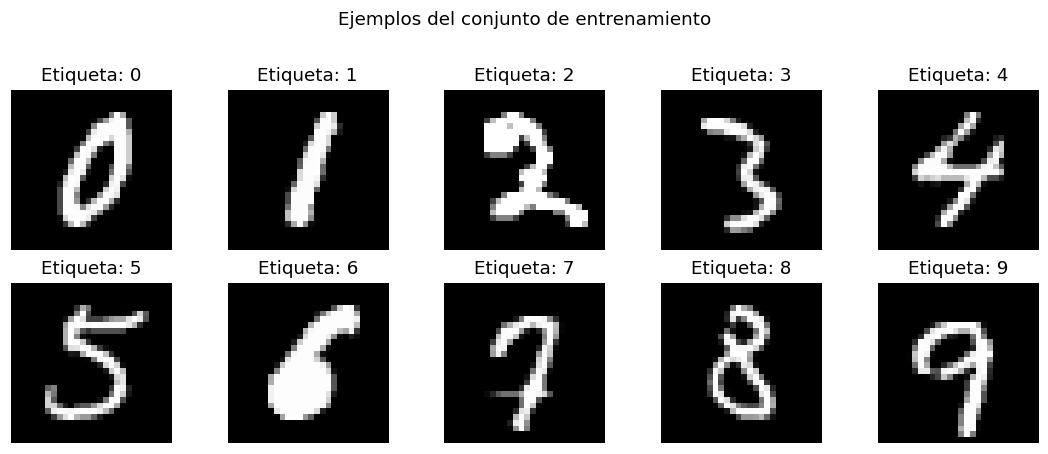

,Dígito,Entrenamiento,Validación,Entrenamiento (%),Validación (%)
0,0,1185,296,9.88,9.87
1,1,1348,337,11.23,11.23
2,2,1192,298,9.93,9.93
3,3,1226,307,10.22,10.23
4,4,1168,292,9.73,9.73
5,5,1084,271,9.03,9.03
6,6,1184,296,9.87,9.87
7,7,1253,313,10.44,10.43
8,8,1170,293,9.75,9.77
9,9,1190,297,9.92,9.90


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digito, ax in enumerate(axes.flat):
    i = np.flatnonzero(y_ent == digito)[0]
    ax.imshow(x_ent[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Etiqueta: {digito}")
    ax.axis("off")
fig.suptitle("Ejemplos del conjunto de entrenamiento", y=1.02)
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "ejemplos_entrenamiento.png", dpi=160, bbox_inches="tight")
plt.show()
conteos = pd.DataFrame({
    "Dígito": np.arange(10),
    "Entrenamiento": np.bincount(y_ent, minlength=10),
    "Validación": np.bincount(y_val, minlength=10)
})
conteos["Entrenamiento (%)"] = 100 * conteos["Entrenamiento"] / len(y_ent)
conteos["Validación (%)"] = 100 * conteos["Validación"] / len(y_val)
display(conteos.round(2))


### Pregunta de interpretación 1

¿Qué diferencia hay entre una imagen, sus píxeles y su etiqueta? ¿Por qué necesitamos
un conjunto de validación separado del entrenamiento?

**Respuesta:** escribe aquí tu explicación.


## 6. Construcción de la red

La función crea **una red nueva** en cada llamada:

1. `Input`: recibe una imagen de 28 × 28.
2. `Rescaling`: divide los píxeles entre 255 **una sola vez**, dentro del modelo.
3. `Flatten`: convierte la imagen en un vector de 784 entradas.
4. `Dense`: capa oculta de 32 o 128 neuronas con ReLU.
5. `Dense`: diez salidas con softmax, una por dígito.

Usamos `sparse_categorical_crossentropy` porque las etiquetas son enteros de 0 a 9.
`accuracy` mide la proporción de predicciones correctas. No es la misma métrica que
*precision* por clase.


In [6]:
def crear_red(neuronas, tasa):
    red = tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28), name="imagen"),
        tf.keras.layers.Rescaling(1.0 / 255.0, name="reescalado"),
        tf.keras.layers.Flatten(name="vector_pixeles"),
        tf.keras.layers.Dense(neuronas, activation="relu", name="capa_oculta"),
        tf.keras.layers.Dense(10, activation="softmax", name="probabilidades")
    ], name=f"mnist_{neuronas}_neuronas")
    red.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=tasa),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return red
modelo_ejemplo = crear_red(neuronas=32, tasa=0.001)
modelo_ejemplo.summary()
del modelo_ejemplo
tf.keras.backend.clear_session()

Model: "mnist_32_neuronas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reescalado (Rescaling)          │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vector_pixeles (Flatten)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta (Dense)             │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Candidatos y preparación de lotes

La cuadrícula contiene seis combinaciones. Usaremos las mismas imágenes y una secuencia
reproducible de lotes para comparar candidatos. `tf.data` organiza los lotes y prepara
los datos que recibirá `fit`.

En entrenamiento se mezclan los ejemplos. En validación y evaluación se conservan en orden.


In [18]:
configuraciones = [
    {"id": f"C{i:02d}", "neuronas": neuronas, "tasa": tasa}
    for i, (neuronas, tasa) in enumerate(product(NEURONAS, TASAS), start=1)
]
display(pd.DataFrame(configuraciones))
def crear_dataset(x, y, entrenar=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if entrenar:
        ds = ds.shuffle(len(y), seed=SEMILLA, reshuffle_each_iteration=True)
    ds = ds.batch(TAM_LOTE)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    opciones.threading.max_intra_op_parallelism = 1
    return ds.with_options(opciones).prefetch(1)
ds_validacion = crear_dataset(x_val, y_val)
ds_ent_evaluacion = crear_dataset(x_ent, y_ent)

,id,neuronas,tasa
0,C01,32,0.0100
1,C02,32,0.0010
2,C03,32,0.0001
3,C04,128,0.0100
4,C05,128,0.0010
5,C06,128,0.0001


## 8. Entrenamiento de las seis configuraciones

Esta es la celda que tarda más. Para cada candidato:

- Se crea una red nueva y un callback nuevo.
- Se entrena durante un máximo de 12 épocas.
- `EarlyStopping` observa `val_loss`, espera tres épocas sin mejora y restaura los mejores pesos.
- Se vuelve a evaluar entrenamiento y validación con **el mismo estado restaurado**.
- Se guardan el modelo, su historial y sus métricas.

El tiempo registrado corresponde a `fit`, sin incluir la evaluación posterior ni el guardado.
Si un candidato falla, el error queda registrado. No se ocultará una comparación incompleta.
El conjunto de prueba **todavía no se utiliza**.


In [19]:
registros = []
historiales = {}
for cfg in configuraciones:
    print("\n" + "=" * 65)
    print(f"{cfg['id']}: {cfg['neuronas']} neuronas, tasa={cfg['tasa']}")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    inicio = time.perf_counter()
    try:
        red = crear_red(cfg["neuronas"], cfg["tasa"])
        parada = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=PACIENCIA,
            restore_best_weights=True
        )
        ds_entrenamiento = crear_dataset(x_ent, y_ent, entrenar=True)
        inicio_fit = time.perf_counter()
        historia = red.fit(
            ds_entrenamiento,
            validation_data=ds_validacion,
            epochs=MAX_EPOCAS,
            callbacks=[parada],
            shuffle=False,
            verbose=2
        )
        segundos_fit = time.perf_counter() - inicio_fit
        h = {k: [float(v) for v in valores]
             for k, valores in historia.history.items()}
        if not np.isfinite(h["val_loss"]).all():
            raise ValueError("El historial contiene pérdidas de validación no finitas.")
        met_ent = red.evaluate(ds_ent_evaluacion, verbose=0, return_dict=True)
        met_val = red.evaluate(ds_validacion, verbose=0, return_dict=True)
        if not np.isfinite([*met_ent.values(), *met_val.values()]).all():
            raise ValueError("La evaluación produjo valores no finitos.")
        ruta_modelo = CANDIDATOS_DIR / f"{cfg['id']}.keras"
        red.save(ruta_modelo)
        historiales[cfg["id"]] = h
        registro = {
            **cfg, "estado": "correcto", "error": "",
            "parametros": int(red.count_params()),
            "epocas_ejecutadas": len(h["loss"]),
            "mejor_epoca": int(np.argmin(h["val_loss"]) + 1),
            "perdida_ent": float(met_ent["loss"]),
            "perdida_val": float(met_val["loss"]),
            "exactitud_ent": float(met_ent["accuracy"]),
            "exactitud_val": float(met_val["accuracy"]),
            "brecha_exactitud_pp": 100 * float(met_ent["accuracy"] - met_val["accuracy"]),
            "segundos_fit": float(segundos_fit),
            "ruta_modelo": str(ruta_modelo)
        }
        print(f"Validación restaurada: pérdida={met_val['loss']:.4f}, "
              f"exactitud={met_val['accuracy']:.4f}")
        del red
    except Exception as error:
        registro = {**cfg, "estado": "fallido", "error": repr(error),
                    "segundos_fit": float(time.perf_counter() - inicio)}
        print("Candidato fallido:", repr(error))
    registros.append(registro)
    pd.DataFrame(registros).to_csv(CARPETA / "resultados_candidatos.csv", index=False)
    (CARPETA / "historiales.json").write_text(
        json.dumps(historiales, indent=2, ensure_ascii=False), encoding="utf-8"
    )
resultados = pd.DataFrame(registros)
correctos = resultados.loc[resultados["estado"] == "correcto"].copy()
if correctos.empty:
    raise RuntimeError("Ningún candidato terminó. Revisa los errores antes de continuar.")
if len(correctos) != len(configuraciones):
    display(resultados.loc[resultados["estado"] != "correcto", ["id", "error"]])
    raise RuntimeError("Comparación incompleta. Corrige los candidatos fallidos y repite el experimento.")
print(f"\nExperimento completo: {len(correctos)} de {len(configuraciones)} candidatos.")


C01: 32 neuronas, tasa=0.01
Epoch 1/12
94/94 - 2s - 21ms/step - accuracy: 0.8500 - loss: 0.4943 - val_accuracy: 0.9067 - val_loss: 0.3213
Epoch 2/12
94/94 - 0s - 3ms/step - accuracy: 0.9300 - loss: 0.2362 - val_accuracy: 0.9270 - val_loss: 0.2592
Epoch 3/12
94/94 - 0s - 4ms/step - accuracy: 0.9449 - loss: 0.1777 - val_accuracy: 0.9347 - val_loss: 0.2397
Epoch 4/12
94/94 - 0s - 3ms/step - accuracy: 0.9557 - loss: 0.1446 - val_accuracy: 0.9273 - val_loss: 0.2559
Epoch 5/12
94/94 - 0s - 3ms/step - accuracy: 0.9607 - loss: 0.1217 - val_accuracy: 0.9340 - val_loss: 0.2467
Epoch 6/12
94/94 - 0s - 4ms/step - accuracy: 0.9653 - loss: 0.1055 - val_accuracy: 0.9367 - val_loss: 0.2451
Validación restaurada: pérdida=0.2397, exactitud=0.9347

C02: 32 neuronas, tasa=0.001
Epoch 1/12
94/94 - 1s - 15ms/step - accuracy: 0.6775 - loss: 1.1456 - val_accuracy: 0.8610 - val_loss: 0.5565
Epoch 2/12
94/94 - 0s - 3ms/step - accuracy: 0.8888 - loss: 0.4357 - val_accuracy: 0.8920 - val_loss: 0.3851
Epoch 3/12


## 9. Tabla comparativa

Ordenaremos por pérdida de validación, de menor a mayor. La pérdida es el criterio principal.
La exactitud, la brecha, el tiempo y el tamaño del modelo ayudan a interpretar el resultado.

`brecha_exactitud_pp` se expresa en **puntos porcentuales**: exactitud de entrenamiento
menos exactitud de validación. No hay un umbral universal que, por sí solo, diagnostique sobreajuste.


,id,neuronas,tasa,parametros,epocas_ejecutadas,mejor_epoca,perdida_ent,perdida_val,exactitud_ent,exactitud_val,brecha_exactitud_pp,segundos_fit
0,C05,128,0.0010,101770,12,12,0.0512,0.1728,0.9899,0.9470,4.2917,8.6944
1,C04,128,0.0100,101770,6,3,0.0696,0.1891,0.9796,0.9433,3.6250,3.8792
2,C01,32,0.0100,25450,6,3,0.1340,0.2397,0.9596,0.9347,2.4917,3.6513
3,C02,32,0.0010,25450,12,12,0.1534,0.2436,0.9577,0.9307,2.7000,5.0229
4,C06,128,0.0001,101770,12,12,0.3031,0.3406,0.9192,0.9010,1.8167,7.0898
5,C03,32,0.0001,25450,12,12,0.4584,0.4823,0.8883,0.8747,1.3667,6.6655


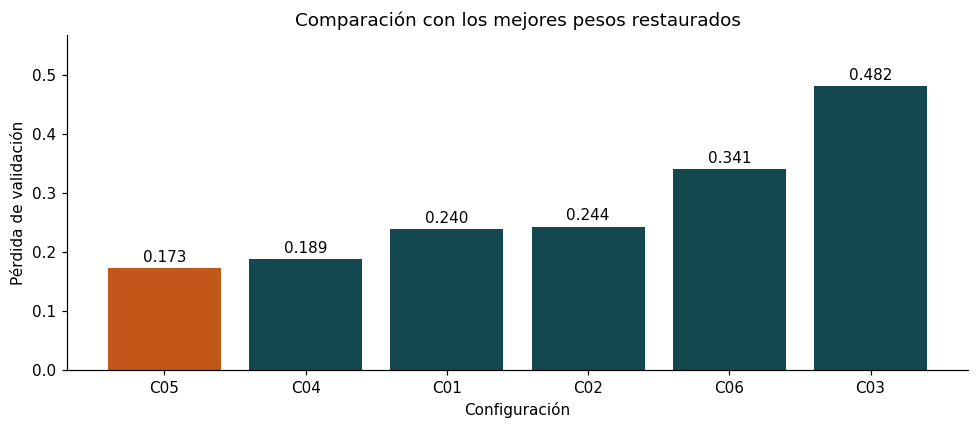

In [20]:
comparacion = correctos.sort_values(["perdida_val", "id"], kind="stable").reset_index(drop=True)
columnas = ["id", "neuronas", "tasa", "parametros", "epocas_ejecutadas", "mejor_epoca",
            "perdida_ent", "perdida_val", "exactitud_ent", "exactitud_val",
            "brecha_exactitud_pp", "segundos_fit"]
display(comparacion[columnas].round(4))
comparacion[columnas].to_csv(CARPETA / "comparacion_ordenada.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
colores = [COLOR_VAL] + [COLOR_ENT] * (len(comparacion) - 1)
ax.bar(comparacion["id"], comparacion["perdida_val"], color=colores)
ax.set(xlabel="Configuración", ylabel="Pérdida de validación",
       title="Comparación con los mejores pesos restaurados")
for i, v in enumerate(comparacion["perdida_val"]):
    ax.annotate(f"{v:.3f}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center")
ax.margins(y=0.18)
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "comparacion_validacion.png", dpi=160)
plt.show()


## 10. Curvas de todos los candidatos

Compara el nivel de las pérdidas, su evolución y la separación entre entrenamiento y
validación. Todos los gráficos usan los mismos límites verticales.
La línea vertical señala la mejor época según `val_loss`.

La pérdida de entrenamiento del historial se registra mientras los pesos cambian durante
la época. Por eso no tiene que coincidir exactamente con la evaluación final de la tabla.


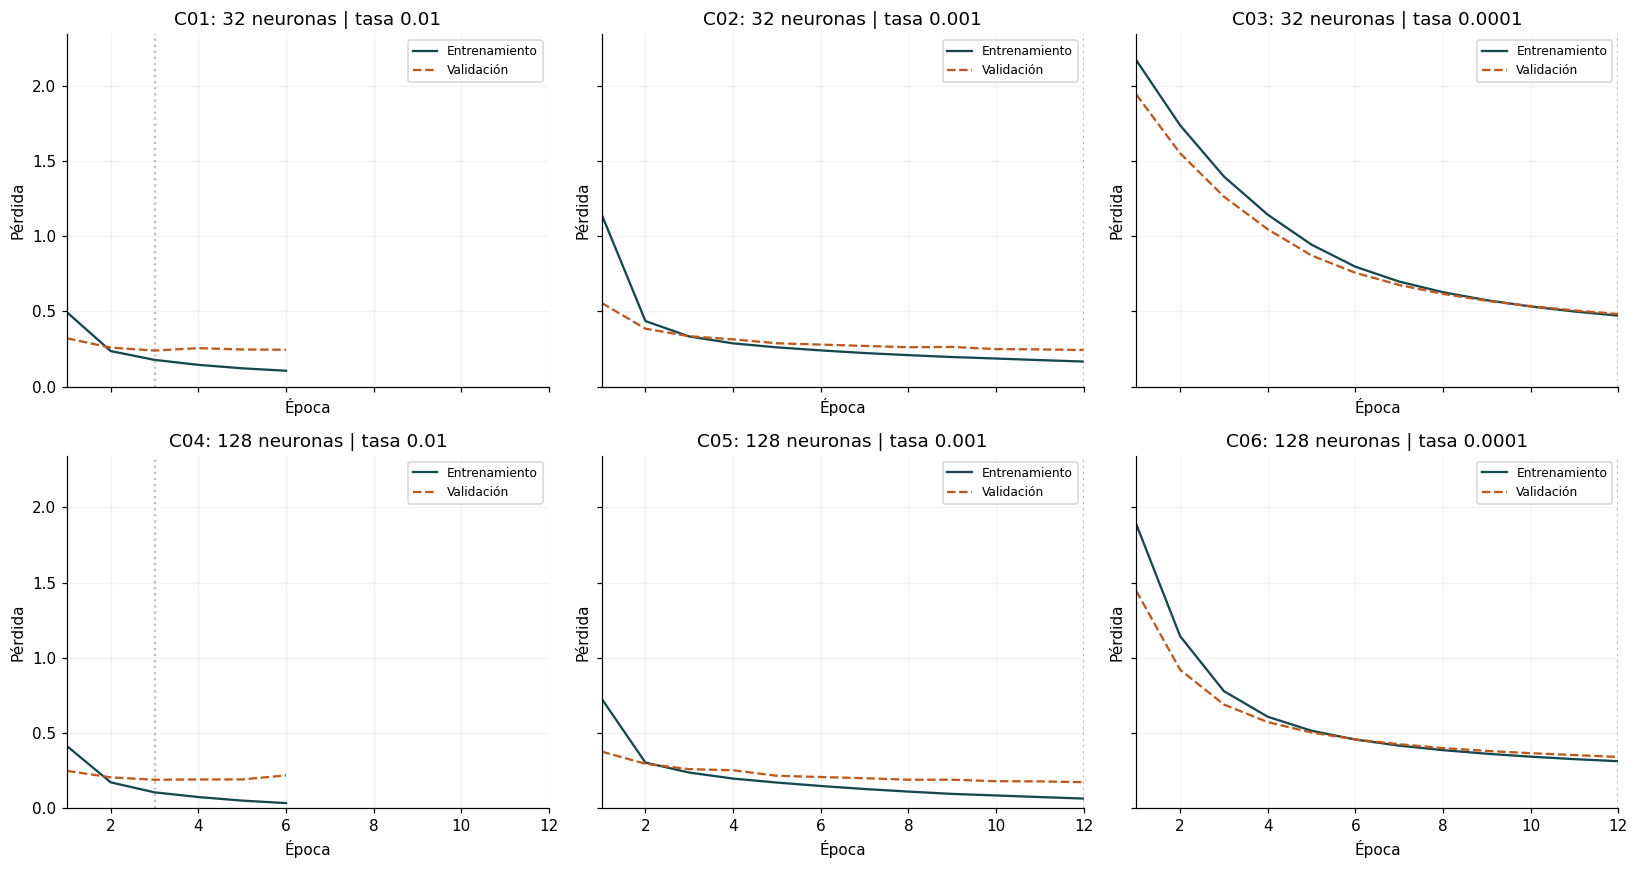

In [21]:
max_perdida = max(max(h["loss"] + h["val_loss"]) for h in historiales.values())
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for cfg, ax in zip(configuraciones, axes.flat):
    h = historiales[cfg["id"]]
    epocas = np.arange(1, len(h["loss"]) + 1)
    mejor_epoca = int(np.argmin(h["val_loss"]) + 1)
    ax.plot(epocas, h["loss"], color=COLOR_ENT, label="Entrenamiento")
    ax.plot(epocas, h["val_loss"], color=COLOR_VAL, linestyle="--", label="Validación")
    ax.axvline(mejor_epoca, color="gray", alpha=0.5, linestyle=":")
    ax.set_title(f"{cfg['id']}: {cfg['neuronas']} neuronas | tasa {cfg['tasa']}")
    ax.set(xlabel="Época", ylabel="Pérdida", xlim=(1, MAX_EPOCAS),
           ylim=(0, max_perdida * 1.08))
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "curvas_seis_candidatos.png", dpi=160)
plt.show()


### Preguntas de interpretación 2

1. ¿Qué configuración obtiene la menor pérdida de validación? ¿También tiene la mayor
   exactitud de entrenamiento?
2. ¿Hay candidatos con señales de subajuste, sobreajuste o entrenamiento todavía incompleto?
   Justifica usando las curvas y la tabla. **No es obligatorio que aparezcan todas las situaciones.**
3. ¿Qué efecto observas al cambiar la tasa manteniendo el número de neuronas?

**Respuestas:** escribe aquí tus observaciones.


## 11. Selección definitiva

Seleccionamos el primer candidato de la tabla ordenada, usando únicamente la pérdida
de validación. En un empate numérico exacto se conserva el identificador menor, criterio
fijado por el orden de la tabla. Una diferencia pequeña no implica una ventaja concluyente.

Cargamos el archivo del candidato elegido: **no creamos una red nueva ni la reentrenamos**.
El modelo conserva los mejores pesos restaurados durante su entrenamiento.


,id,neuronas,tasa_aprendizaje,criterio,perdida_validacion,exactitud_validacion,mejor_epoca
0,C05,128,0.001,Menor perdida de validacion despues de restaur...,0.172812,0.947,12


La configuración queda fijada antes de consultar la prueba.


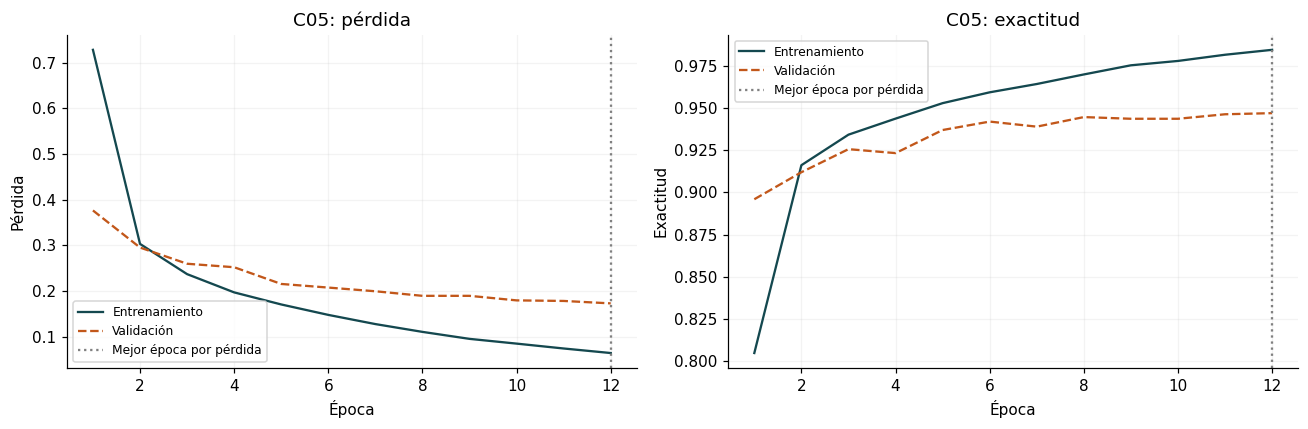

In [22]:
fila_mejor = comparacion.iloc[0]
ID_MEJOR = str(fila_mejor["id"])
mejor_modelo = tf.keras.models.load_model(str(fila_mejor["ruta_modelo"]))
seleccion = {
    "id": ID_MEJOR,
    "neuronas": int(fila_mejor["neuronas"]),
    "tasa_aprendizaje": float(fila_mejor["tasa"]),
    "criterio": "Menor perdida de validacion despues de restaurar los mejores pesos",
    "perdida_validacion": float(fila_mejor["perdida_val"]),
    "exactitud_validacion": float(fila_mejor["exactitud_val"]),
    "mejor_epoca": int(fila_mejor["mejor_epoca"])
}
(CARPETA / "seleccion_antes_de_prueba.json").write_text(
    json.dumps(seleccion, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.DataFrame([seleccion]))
print("La configuración queda fijada antes de consultar la prueba.")

h = historiales[ID_MEJOR]
epocas = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica, titulo in zip(axes, ["loss", "accuracy"], ["Pérdida", "Exactitud"]):
    ax.plot(epocas, h[metrica], color=COLOR_ENT, label="Entrenamiento")
    ax.plot(epocas, h[f"val_{metrica}"], color=COLOR_VAL, linestyle="--", label="Validación")
    ax.axvline(seleccion["mejor_epoca"], color="gray", linestyle=":", label="Mejor época por pérdida")
    ax.set(xlabel="Época", ylabel=titulo, title=f"{ID_MEJOR}: {titulo.lower()}")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "curvas_modelo_elegido.png", dpi=160)
plt.show()


### Pregunta de interpretación 3

¿La mejor época coincide con la última ejecutada? Explica qué aporta
`restore_best_weights=True` cuando estas épocas son diferentes.

**Respuesta:** escribe aquí tu explicación.


## 12. Evaluación final en prueba

Ahora sí utilizaremos las 10.000 imágenes del conjunto oficial de prueba. Calcularemos
pérdida, exactitud, métricas por clase y matriz de confusión **solo del modelo elegido**.

Las filas de la matriz representan las clases reales; las columnas, las clases predichas.
Los aciertos se encuentran en la diagonal.

Después de consultar esta evaluación, no se deben volver a elegir hiperparámetros usando
este resultado. Si el test de MNIST ya fue observado en la clase anterior, esta evaluación
es una práctica didáctica sobre un benchmark conocido, no un conjunto nuevo y completamente ciego.


,Conjunto,Pérdida,Exactitud
0,Entrenamiento,0.0512,0.9899
1,Validación,0.1728,0.9470
2,Prueba,0.1497,0.9553


,precision,recall,f1-score,support
0,0.9620,0.9827,0.9722,980.0000
1,0.9730,0.9841,0.9785,1135.0000
2,0.9550,0.9467,0.9509,1032.0000
3,0.9452,0.9554,0.9503,1010.0000
4,0.9569,0.9501,0.9535,982.0000
5,0.9503,0.9439,0.9471,892.0000
6,0.9574,0.9614,0.9594,958.0000
7,0.9544,0.9572,0.9558,1028.0000
8,0.9486,0.9281,0.9382,974.0000
9,0.9470,0.9386,0.9428,1009.0000


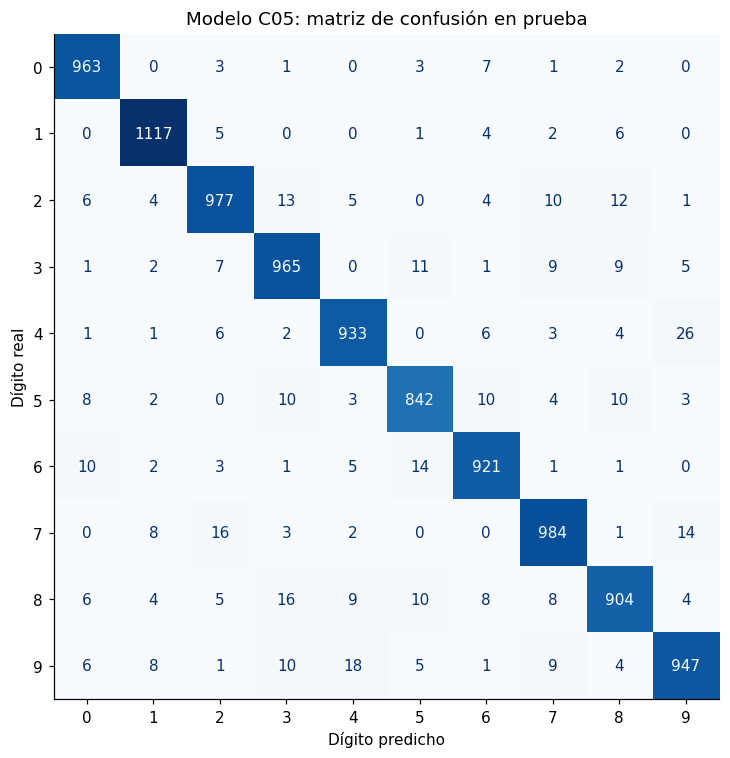

In [23]:
ds_prueba = crear_dataset(x_prueba, y_prueba)
metricas_prueba = mejor_modelo.evaluate(ds_prueba, verbose=0, return_dict=True)
probabilidades = mejor_modelo.predict(ds_prueba, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)
assert probabilidades.shape == (len(y_prueba), 10)
np.testing.assert_allclose(probabilidades.sum(axis=1), 1.0, atol=1e-5)
exactitud_sklearn = accuracy_score(y_prueba, y_pred)
np.testing.assert_allclose(metricas_prueba["accuracy"], exactitud_sklearn, atol=1e-6)
resumen_evaluacion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Pérdida": [float(fila_mejor["perdida_ent"]), float(fila_mejor["perdida_val"]),
                float(metricas_prueba["loss"])],
    "Exactitud": [float(fila_mejor["exactitud_ent"]), float(fila_mejor["exactitud_val"]),
                  float(metricas_prueba["accuracy"])]
})
display(resumen_evaluacion.round(4))
resumen_evaluacion.to_csv(CARPETA / "evaluacion_modelo_elegido.csv", index=False)

informe = classification_report(y_prueba, y_pred, labels=np.arange(10),
                                 target_names=[str(i) for i in range(10)],
                                 output_dict=True, zero_division=0)
tabla_informe = pd.DataFrame(informe).T
display(tabla_informe.round(4))
tabla_informe.to_csv(CARPETA / "reporte_clasificacion.csv", index_label="clase")

matriz = confusion_matrix(y_prueba, y_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(matriz, display_labels=np.arange(10)).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set(title=f"Modelo {ID_MEJOR}: matriz de confusión en prueba",
       xlabel="Dígito predicho", ylabel="Dígito real")
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "matriz_confusion_prueba.png", dpi=160)
plt.show()


## 13. Inspección de aciertos y errores

La exactitud resume el conjunto, pero no muestra cómo son los casos que fallan.
Observaremos ejemplos de ambas situaciones y las confusiones más frecuentes.
El valor softmax más alto es una puntuación del modelo, no una garantía de acierto.


Aciertos: 9553 | Errores: 447


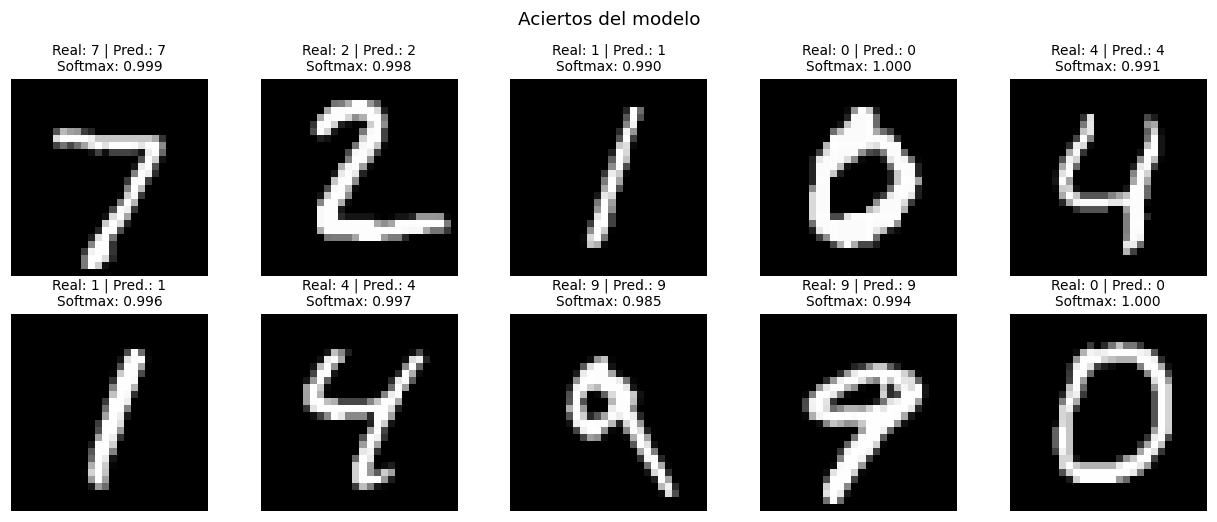

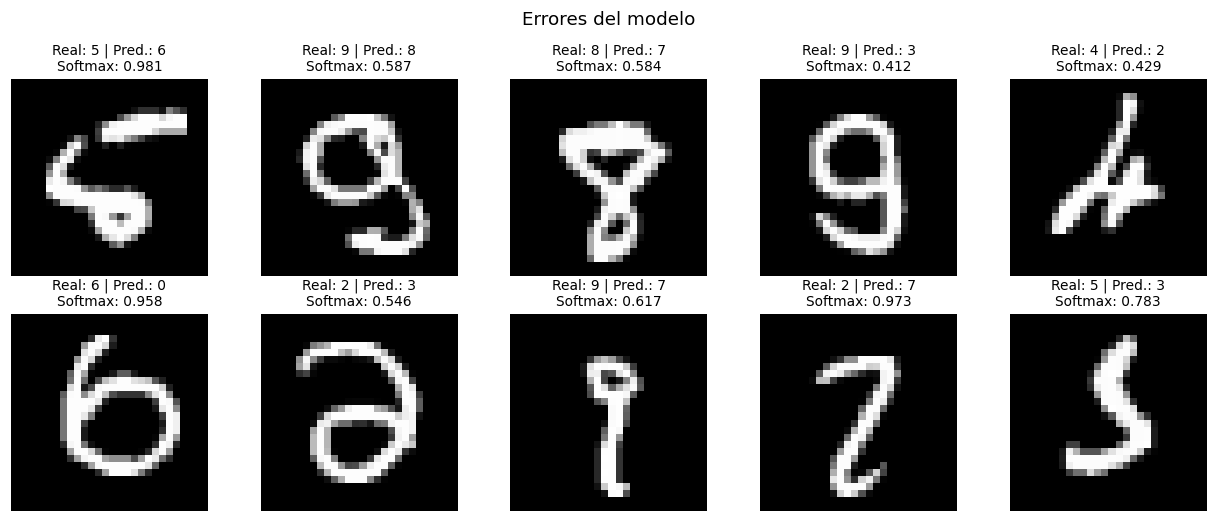

,Dígito real,Dígito predicho,Casos
34,4,9,26
70,9,4,18
52,7,2,16
60,8,3,16
48,6,5,14


In [24]:
def mostrar_predicciones(indices, titulo, maximo=10):
    indices = np.asarray(indices)[:maximo]
    if len(indices) == 0:
        print(f"{titulo}: no se encontraron casos.")
        return
    columnas = min(5, len(indices))
    filas = int(np.ceil(len(indices) / columnas))
    fig, axes = plt.subplots(filas, columnas, figsize=(2.3 * columnas, 2.4 * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, indices):
        ax.imshow(x_prueba[i], cmap="gray", vmin=0, vmax=255)
        p = probabilidades[i, y_pred[i]]
        ax.set_title(f"Real: {y_prueba[i]} | Pred.: {y_pred[i]}\nSoftmax: {p:.3f}", fontsize=9)
    fig.suptitle(titulo)
    fig.tight_layout()
    nombre = "aciertos_prueba.png" if titulo.startswith("Aciertos") else "errores_prueba.png"
    fig.savefig(FIGURAS_DIR / nombre, dpi=160, bbox_inches="tight")
    plt.show()

idx_aciertos = np.flatnonzero(y_pred == y_prueba)
idx_errores = np.flatnonzero(y_pred != y_prueba)
print("Aciertos:", len(idx_aciertos), "| Errores:", len(idx_errores))
mostrar_predicciones(idx_aciertos, "Aciertos del modelo")
mostrar_predicciones(idx_errores, "Errores del modelo")

confusiones = [{"Dígito real": i, "Dígito predicho": j, "Casos": int(matriz[i, j])}
               for i in range(10) for j in range(10) if i != j and matriz[i, j] > 0]
tabla_confusiones = pd.DataFrame(confusiones, columns=["Dígito real", "Dígito predicho", "Casos"])
display(tabla_confusiones.sort_values("Casos", ascending=False).head(5))


### Preguntas de interpretación 4

1. ¿Qué pares de dígitos confunde con mayor frecuencia el modelo? Usa la matriz y los ejemplos.
2. ¿Cómo se compara la exactitud de prueba con la de validación?
3. ¿Por qué una imagen fotografiada con otro fondo, iluminación o tamaño puede fallar
   aunque el modelo funcione bien en MNIST?

**Respuestas:** escribe aquí tus observaciones.


## 14. Guardar el modelo y preparar el laboratorio 25

El siguiente bloque crea un paquete con:

- `modelo_mnist.keras`, con el reescalado incorporado.
- La configuración, las versiones y los resultados del experimento.
- Tablas CSV, historiales y gráficas.
- Los índices de las particiones.
- Diez imágenes PNG, una por clase real, y un lote de ejemplo para comprobar la carga.

Se comprueba que el modelo cargado reproduce las probabilidades del modelo elegido.
El ZIP incluirá únicamente el modelo final, no los seis archivos candidatos.


In [25]:
ENTREGABLES = CARPETA / "para_laboratorio25"
ENTREGABLES.mkdir(exist_ok=True)
RUTA_MODELO = ENTREGABLES / "modelo_mnist.keras"
mejor_modelo.save(RUTA_MODELO)
modelo_recargado = tf.keras.models.load_model(RUTA_MODELO, compile=False)
lote_verificacion = x_val[:8]
p_antes = mejor_modelo(lote_verificacion, training=False).numpy()
p_despues = modelo_recargado(lote_verificacion, training=False).numpy()
np.testing.assert_allclose(p_antes, p_despues, rtol=1e-5, atol=1e-6)
print("Carga verificada: las probabilidades coinciden dentro de la tolerancia.")

versiones = {"python": sys.version.split()[0], "tensorflow": tf.__version__,
             "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__,
             "matplotlib": version_paquete("matplotlib"),
             "Pillow": version_paquete("Pillow")}
configuracion_final = {
    "dataset": "MNIST", "id_ejecucion": ID_EJECUCION, "semilla": SEMILLA,
    "n_entrenamiento": len(y_ent), "n_validacion": len(y_val), "n_prueba": len(y_prueba),
    "candidatos": configuraciones, "seleccion": seleccion,
    "lote": TAM_LOTE, "max_epocas": MAX_EPOCAS, "paciencia": PACIENCIA,
    "versiones": versiones,
    "entrada": {"forma_por_imagen": [28, 28], "rango_externo": [0, 255],
                "canales": "escala de grises", "convencion": "trazo claro, fondo oscuro",
                "reescalado_integrado": True},
    "clases": list(range(10)),
    "prueba": {k: float(v) for k, v in metricas_prueba.items()}
}
(ENTREGABLES / "configuracion_y_resultados.json").write_text(
    json.dumps(configuracion_final, indent=2, ensure_ascii=False), encoding="utf-8")
(ENTREGABLES / "requirements_lab24.txt").write_text(
    "\n".join(f"{paquete}=={v}" for paquete, v in versiones.items() if paquete != "python") + "\n",
    encoding="utf-8")

for nombre in ["resultados_candidatos.csv", "comparacion_ordenada.csv", "historiales.json",
               "evaluacion_modelo_elegido.csv", "reporte_clasificacion.csv",
               "seleccion_antes_de_prueba.json", "indices_particiones.npz"]:
    shutil.copy2(CARPETA / nombre, ENTREGABLES / nombre)
shutil.copytree(FIGURAS_DIR, ENTREGABLES / "figuras", dirs_exist_ok=True)

predicciones_df = pd.DataFrame({
    "indice_prueba": np.arange(len(y_prueba)), "etiqueta_real": y_prueba,
    "etiqueta_predicha": y_pred, "softmax_maximo": probabilidades.max(axis=1),
    "acierto": y_pred == y_prueba
})
predicciones_df.to_csv(ENTREGABLES / "predicciones_prueba.csv", index=False)

ejemplos_dir = ENTREGABLES / "ejemplos_png"
ejemplos_dir.mkdir(exist_ok=True)
idx_ejemplos = np.array([np.flatnonzero(y_prueba == d)[0] for d in range(10)])
for digito, i in enumerate(idx_ejemplos):
    Image.fromarray(x_prueba[i]).save(ejemplos_dir / f"digito_real_{digito}.png")
np.savez_compressed(ENTREGABLES / "ejemplos_mnist.npz",
                    imagenes=x_prueba[idx_ejemplos], etiquetas=y_prueba[idx_ejemplos])

texto_lectura = """LABORATORIO 24 - MNIST
El modelo final está en modelo_mnist.keras.
Cargar con tf.keras.models.load_model(ruta, compile=False) para inferencia.
Entrada: lote con forma (n, 28, 28), escala de grises e intensidades 0-255.
No dividir de nuevo entre 255: el modelo incluye Rescaling.
Salida: diez puntuaciones softmax, en el orden de clases 0 a 9.
Los PNG conservan el tamaño y la convención visual de MNIST.
Las etiquetas de los archivos indican la clase real, no garantizan la predicción.
Las versiones probadas durante ESTA ejecución están en configuracion_y_resultados.json.
Gradio se incorporará en el laboratorio 25; todavía no es necesario en el laboratorio 24.
Conservar también el notebook con las respuestas y sus resultados.
"""
(ENTREGABLES / "LEEME.txt").write_text(texto_lectura, encoding="utf-8")
RUTA_ZIP = Path(shutil.make_archive(str(CARPETA / "Laboratorio_24_MNIST_resultados"),
                                   "zip", root_dir=ENTREGABLES))
print("Modelo:", RUTA_MODELO.resolve())
print("ZIP:", RUTA_ZIP.resolve())
print(f"Tamaño del ZIP: {RUTA_ZIP.stat().st_size / 1024**2:.2f} MB")


Carga verificada: las probabilidades coinciden dentro de la tolerancia.
Modelo: /content/laboratorio24_mnist/20261106_200022_397445/para_laboratorio25/modelo_mnist.keras
ZIP: /content/laboratorio24_mnist/20261106_200022_397445/Laboratorio_24_MNIST_resultados.zip
Tamaño del ZIP: 1.67 MB


## 15. Descarga de resultados

Ejecuta esta celda para descargar el ZIP en Colab. Fuera de Colab se mostrará un enlace
al archivo. Descarga también este notebook desde **Archivo → Descargar → Descargar .ipynb**
después de escribir las respuestas.


In [16]:
DESCARGAR_ZIP = True
if DESCARGAR_ZIP:
    try:
        from google.colab import files
    except ImportError:
        display(FileLink(str(RUTA_ZIP)))
    else:
        files.download(str(RUTA_ZIP))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Conclusión del laboratorio

Redacta una conclusión basada en **tus resultados**. Incluye:

- La configuración elegida y la métrica que sustentó la decisión.
- Lo observado al cambiar la tasa y el número de neuronas.
- Las señales de subajuste o sobreajuste que realmente aparecieron, si las hubo.
- El desempeño de prueba y los errores más frecuentes.
- Una limitación del experimento y el formato de entrada requerido por el modelo guardado.

**Conclusión del estudiante:**

Escribe aquí tu conclusión.

### Revisión antes de terminar

- [ ] Se compararon correctamente los seis candidatos.
- [ ] La selección utilizó validación y la prueba se evaluó después.
- [ ] Las interpretaciones se sustentan en curvas, tablas y ejemplos.
- [ ] El modelo guardado se volvió a cargar y sus salidas se verificaron.
- [ ] Se descargaron el notebook y el ZIP para continuar con el laboratorio 25.


## Referencias de consulta

- [Keras: MNIST](https://keras.io/api/datasets/mnist/).
- [Keras: EarlyStopping](https://keras.io/api/callbacks/early_stopping/).
- [Keras: Rescaling](https://keras.io/api/layers/preprocessing_layers/image_preprocessing/rescaling/).
- [Keras: guardado y carga](https://keras.io/guides/serialization_and_saving/).
- [scikit-learn: train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).
- [scikit-learn: classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).

Este notebook realiza una búsqueda en cuadrícula con una partición fija de validación.
No realiza validación cruzada ni busca demostrar superioridad estadística entre configuraciones.
